In [1]:
from visualisation_donnees import charger_routes, charger_trips, charger_parcours

df_routes = charger_routes("data/idfm")
df_routes.head(20)

,route_id,agency_id,route_short_name,route_type,route_color,route_text_color,mode
456,IDFM:C01371,IDFM:Operator_100,1,1,FFBE00,000000,metro
457,IDFM:C01372,IDFM:Operator_100,2,1,0055C8,FFFFFF,metro
458,IDFM:C01373,IDFM:Operator_100,3,1,6E6E00,FFFFFF,metro
462,IDFM:C01384,IDFM:Operator_100,14,1,640082,FFFFFF,metro
463,IDFM:C01386,IDFM:Operator_100,3B,1,82C8E6,000000,metro
464,IDFM:C01387,IDFM:Operator_100,7B,1,82DC73,000000,metro
475,IDFM:C01377,IDFM:Operator_100,7,1,FF82B4,000000,metro
1234,IDFM:C01383,IDFM:Operator_100,13,1,82C8E6,000000,metro
1355,IDFM:C01374,IDFM:Operator_100,4,1,A0006E,FFFFFF,metro
1356,IDFM:C01375,IDFM:Operator_100,5,1,FF5A00,000000,metro


In [2]:
df_trips = charger_trips("data/idfm", df_routes)
df_trips.head()

,route_id,trip_id,shape_id,agency_id,route_short_name,route_type,route_color,route_text_color,mode
0,IDFM:C01381,IDFM:RATP:COU_RATP_11DIGAILLAC_2026_Chat01Robp...,IDFM:shp_1_41,IDFM:Operator_100,11,1,6E491E,FFFFFF,metro
1,IDFM:C01381,IDFM:RATP:COU_RATP_11DIGAILLAC_2026_Robp02Robp...,IDFM:shp_1_41,IDFM:Operator_100,11,1,6E491E,FFFFFF,metro
2,IDFM:C01381,IDFM:RATP:COU_RATP_11DIGAILLAC_2026_PteL01Chat...,IDFM:shp_1_119,IDFM:Operator_100,11,1,6E491E,FFFFFF,metro
3,IDFM:C01381,IDFM:RATP:COU_RATP_11DIGAILLAC_2026_Robp02Robp...,IDFM:shp_1_222,IDFM:Operator_100,11,1,6E491E,FFFFFF,metro
4,IDFM:C01381,IDFM:RATP:COU_RATP_11DIGAILLAC_2026_Robp01Robp...,IDFM:shp_1_220,IDFM:Operator_100,11,1,6E491E,FFFFFF,metro


In [3]:
df_parcours = charger_parcours("data/idfm", df_trips)
df_parcours.head()

,shape_id,shape_pt_lat,shape_pt_lon,shape_pt_sequence,route_id,agency_id,route_short_name,route_type,route_color,route_text_color,mode
16670,IDFM:shp_1_100,48.848721,2.298968,0,IDFM:C01376,IDFM:Operator_100,6,1,82DC73,000000,metro
16671,IDFM:shp_1_100,48.847824,2.301867,1,IDFM:C01376,IDFM:Operator_100,6,1,82DC73,000000,metro
16672,IDFM:shp_1_100,48.847511,2.302942,2,IDFM:C01376,IDFM:Operator_100,6,1,82DC73,000000,metro
16673,IDFM:shp_1_100,48.847511,2.302942,3,IDFM:C01376,IDFM:Operator_100,6,1,82DC73,000000,metro
16674,IDFM:shp_1_100,48.846603,2.306028,4,IDFM:C01376,IDFM:Operator_100,6,1,82DC73,000000,metro


In [4]:
import geopandas as gpd
import pandas as pd
from visualisation_donnees import (
    charger_routes, charger_trips, charger_parcours,
    construire_lignes_idfm, charger_arrets, charger_stations,
)

df_routes = charger_routes("data/idfm")
df_trips = charger_trips("data/idfm", df_routes)
df_parcours = charger_parcours("data/idfm", df_trips)
gpd_idfm = construire_lignes_idfm(df_parcours)
df_arrets = charger_arrets("data/idfm", df_trips)
df_stations = charger_stations("data/idfm", df_arrets)

In [5]:
gpd_stations = gpd.GeoDataFrame(
    df_stations,
    geometry=gpd.points_from_xy(df_stations["stop_lon"], df_stations["stop_lat"]),
    crs="EPSG:4326",
).to_crs("EPSG:2154")

In [6]:
gpd_idfm["longueur"] = gpd_idfm.length
trace_ref = gpd_idfm.sort_values("longueur", ascending=False).drop_duplicates("route_id")
trace_ref = pd.DataFrame(trace_ref[["route_id", "geometry"]]).rename(columns={"geometry": "trace"})

In [7]:
stations = gpd_stations.merge(trace_ref, on="route_id")

# distance entre la station et le tracé (pour repérer les stations d'une autre branche)
stations["distance_trace"] = stations.apply(lambda r: r["trace"].distance(r["geometry"]), axis=1)
# position le long du tracé, en km
stations["position_km"] = stations.apply(lambda r: r["trace"].project(r["geometry"]) / 1000, axis=1)

stations = stations[stations["distance_trace"] < 300]
stations = stations.sort_values(["route_short_name", "position_km"])

In [8]:
# faire commencer chaque ligne à 0 km
stations["position_km"] = stations["position_km"] - stations.groupby("route_short_name")["position_km"].transform("min")

# arrondir à 1 chiffre après la virgule
stations["position_km"] = stations["position_km"].round(2)

In [9]:
stations.loc[stations["route_short_name"] == "6", ["stop_name", "position_km"]]

,stop_name,position_km
450,Charles de Gaulle - Étoile,0.00
293,Kléber,0.51
416,Boissière,1.02
473,Trocadéro,1.48
511,Passy,2.15
528,Bir-Hakeim,2.67
559,Dupleix,3.06
555,La Motte-Picquet - Grenelle,3.57
548,Cambronne,3.85
586,Sèvres-Lecourbe,4.55


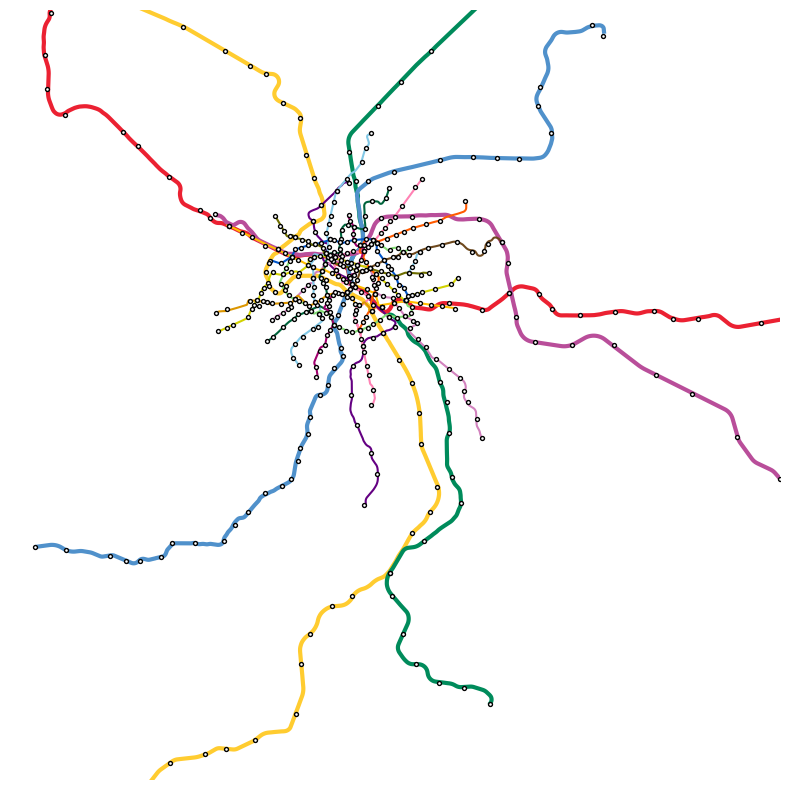

In [10]:
import matplotlib.pyplot as plt
import numpy as np

# le tracé le plus long de chaque ligne (avec ses couleurs)
traces = gpd_idfm.sort_values("longueur", ascending=False).drop_duplicates("route_id")

ax = traces.plot(
    color="#" + traces["route_color"],
    linewidth=np.where(traces["mode"] == "metro", 1.5, 3),  # RER plus épais
    figsize=(10, 10),
)
stations.plot(ax=ax, color="white", edgecolor="black", markersize=8, zorder=5)

ax.set_xlim(630_000, 680_000)  # zoom sur Paris et la petite couronne
ax.set_ylim(6_830_000, 6_880_000)
ax.set_axis_off()
plt.savefig("carte_lignes_idfm.png", dpi=300, bbox_inches="tight")
plt.show()

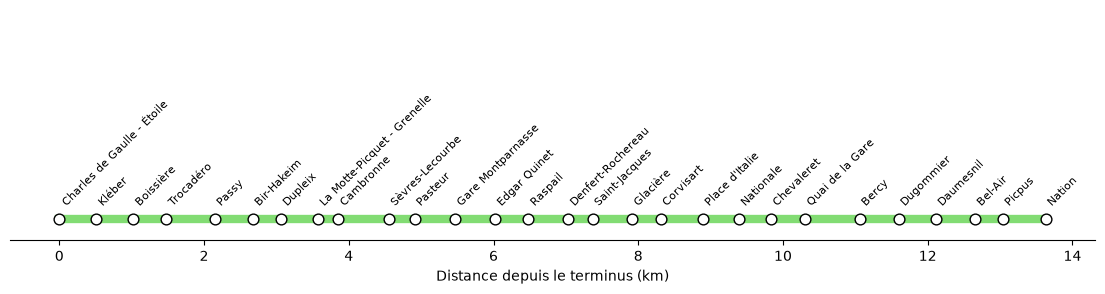

In [11]:
num = "6"
arrets = stations[stations["route_short_name"] == num].sort_values("position_km")
couleur = "#" + arrets["route_color"].iloc[0]

fig, ax = plt.subplots(figsize=(14, 3))
ax.plot(arrets["position_km"], [0] * len(arrets), color=couleur, linewidth=6)
ax.scatter(arrets["position_km"], [0] * len(arrets),
           color="white", edgecolor="black", s=60, zorder=3)

for _, a in arrets.iterrows():
    ax.annotate(
        a["stop_name"],
        xy=(a["position_km"], 0),         
        xytext=(0, 8),                     
        textcoords="offset points",
        rotation=45, fontsize=8,
        ha="left", va="bottom",
    )

ax.set_xlabel("Distance depuis le terminus (km)")
ax.set_yticks([])
ax.spines[["left", "top", "right"]].set_visible(False)
ax.set_ylim(-0.1, 1)
plt.show()

In [12]:
%pip install cartiflette


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [13]:
%pip install ipywidgets


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [19]:
#CELLULE A 
df_mob = pd.read_parquet("RP2023_mobpro.parquet")
print(df_mob.columns.tolist())

['COMMUNE', 'ARM', 'DCFLT', 'DCLT', 'AGEREVQ', 'GS', 'DEROU', 'DIPL', 'EMPL', 'ILT', 'ILTUU', 'IMMI', 'INATC', 'INEEM', 'INPOM', 'INPSM', 'IPONDI', 'LPRM', 'METRODOM', 'MOCO', 'NA5', 'NPERR', 'REGION', 'REGLT', 'SEXE', 'STAT', 'STOCD', 'TP', 'TRANS', 'TYPL', 'TYPMR', 'VOIT']


In [20]:
# CELLULE B : préparer MOBPRO

# On garde seulement l'Île-de-France (code région 11)
df_mob = df_mob[df_mob["REGION"].astype(str) == "11"].copy()

# Codes en texte, pour pouvoir les comparer aux dictionnaires
df_mob["COMMUNE"] = df_mob["COMMUNE"].astype(str)
df_mob["GS"] = df_mob["GS"].astype(str)
df_mob["TRANS"] = df_mob["TRANS"].astype(str)

# Noms en clair
noms_csp = {
    "1": "Agriculteurs",
    "2": "Artisans, commerçants, chefs d'entreprise",
    "3": "Cadres",
    "4": "Professions intermédiaires",
    "5": "Employés",
    "6": "Ouvriers",
}
noms_mode = {
    "1": "Pas de transport",
    "2": "Marche",
    "3": "Vélo",
    "4": "Deux-roues motorisé",
    "5": "Voiture",
    "6": "Transports en commun",
}
df_mob["CSP"] = df_mob["GS"].map(noms_csp)
df_mob["mode"] = df_mob["TRANS"].map(noms_mode)

# True si la personne va travailler en transports en commun
df_mob["tc"] = df_mob["mode"] == "Transports en commun"


def joli(serie):  # joli affichage : sans .0 et avec espaces entre les milliers
    """Arrondit, enlève le .0 et sépare les milliers par un espace"""
    return serie.round().astype(int).map(lambda x: f"{x:,}".replace(",", " "))


# Données pondérées grâce à la colonne IPONDI
print(joli(df_mob.groupby("CSP")["IPONDI"].sum().sort_values(ascending=False)))
print()
print(joli(df_mob.groupby("mode")["IPONDI"].sum().sort_values(ascending=False)))

CSP
Cadres                                       2 000 706
Professions intermédiaires                   1 418 387
Employés                                     1 335 778
Ouvriers                                       683 307
Artisans, commerçants, chefs d'entreprise      317 268
Agriculteurs                                     5 393
Name: IPONDI, dtype: str

mode
Transports en commun    2 519 315
Voiture                 2 203 234
Marche                    414 172
Vélo                      284 624
Pas de transport          199 449
Deux-roues motorisé       140 044
Name: IPONDI, dtype: str


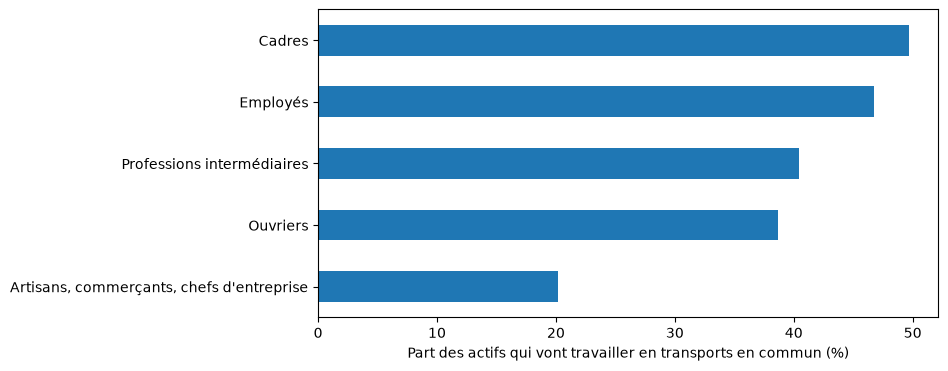

In [21]:
#CELLULE C
df_mob["poids_tc"] = df_mob["IPONDI"] * df_mob["tc"]
somme = df_mob.groupby("CSP")[["poids_tc", "IPONDI"]].sum()
part_tc = somme["poids_tc"] / somme["IPONDI"] * 100

part_tc = part_tc.drop("Agriculteurs")  # trop peu nombreux pour être fiables

ax = part_tc.sort_values().plot(kind="barh", color="#1f77b4", figsize=(8, 4))
ax.set_xlabel("Part des actifs qui vont travailler en transports en commun (%)")
ax.set_ylabel("")
plt.show()

#visualisation num 6 

In [22]:
#CELLULE D : récuper les délimitation des communes 
import numpy as np

url = "https://raw.githubusercontent.com/gregoiredavid/france-geojson/master/regions/ile-de-france/communes-ile-de-france.geojson"
communes = gpd.read_file(url)

communes = communes.rename(columns={"code": "INSEE_COM"})
communes = communes.to_crs("EPSG:2154")[["INSEE_COM", "nom", "geometry"]]
communes.head()

,INSEE_COM,nom,geometry
0,77322,Moussy-le-Neuf,"POLYGON ((671540.099 6888415.654, 672018.657 6..."
1,77323,Moussy-le-Vieux,"POLYGON ((670847.005 6881770.499, 670814.257 6..."
2,91247,Forêt-le-Roi,"POLYGON ((628602.786 6818686.939, 628098.295 6..."
3,94001,Ablon-sur-Seine,"POLYGON ((656675.727 6847486.201, 657009.353 6..."
4,94018,Charenton-le-Pont,"POLYGON ((657381.09 6857583.672, 657109.665 68..."


In [23]:
#CELLULE D bis : trouver l'arrondissement + données georgraphiques de paris
url_arr = "https://opendata.paris.fr/api/explore/v2.1/catalog/datasets/arrondissements/exports/geojson"
arr = gpd.read_file(url_arr)
arr = arr.rename(columns={"c_arinsee": "INSEE_COM", "l_ar": "nom"})
arr["INSEE_COM"] = arr["INSEE_COM"].astype(int).astype(str)
arr["nom"] = arr["INSEE_COM"].str[-2:].astype(int).map(lambda n: "1er" if n == 1 else f"{n}ème")
arr = arr.to_crs("EPSG:2154")[["INSEE_COM", "nom", "geometry"]]

communes = pd.concat([communes[communes["INSEE_COM"] != "75056"], arr], ignore_index=True)
communes.tail()

,INSEE_COM,nom,geometry
1290,75119,19ème,"POLYGON ((655238.908 6866974.758, 655290.661 6..."
1291,75113,13ème,"POLYGON ((654119.17 6859954.677, 654269.366 68..."
1292,75107,7ème,"POLYGON ((648698.567 6861464.29, 648584.964 68..."
1293,75101,1er,"POLYGON ((650706.58 6863530.88, 650848.899 686..."
1294,75103,3ème,"POLYGON ((653331.96 6863240.808, 653336.416 68..."


In [24]:
#CELLULE E
stations_com = gpd.sjoin(
    stations.drop(columns=["trace"]),
    communes,
    predicate="within",
)
stations_com[["route_short_name", "stop_name", "nom"]].head(10)

,route_short_name,stop_name,nom
155,1,La Défense,Puteaux
343,1,Esplanade de la Défense,Puteaux
376,1,Pont de Neuilly,Neuilly-sur-Seine
40,1,Les Sablons,Neuilly-sur-Seine
402,1,Neuilly - Porte Maillot,17ème
448,1,Argentine,17ème
452,1,Charles de Gaulle - Étoile,8ème
429,1,George V,8ème
431,1,Franklin D. Roosevelt,8ème
414,1,Champs-Élysées - Clemenceau,8ème


In [25]:
#CELLULE F
# code géographique : l'arrondissement si on habite Paris, sinon la commune
df_mob["code_geo"] = np.where(
    df_mob["COMMUNE"] == "75056", df_mob["ARM"].astype(str), df_mob["COMMUNE"]
)

df_mob["poids_ouv"] = df_mob["IPONDI"] * (df_mob["CSP"] == "Ouvriers")
somme = df_mob.groupby("code_geo")[["poids_ouv", "IPONDI"]].sum()
part_ouv = (somme["poids_ouv"] / somme["IPONDI"] * 100).round(1).rename("part_ouvriers")

# on enlève l'ancienne colonne si la cellule a déjà été lancée (évite les doublons)
stations_com = stations_com.drop(columns=["part_ouvriers"], errors="ignore")
stations_com = stations_com.merge(part_ouv, left_on="INSEE_COM", right_index=True, how="left")

stations_com[["stop_name", "nom", "part_ouvriers"]].rename(
    columns={"stop_name": "Station", "nom": "Commune", "part_ouvriers": "Part d'ouvriers (%)"}
).head(10)

,Station,Commune,Part d'ouvriers (%)
155,La Défense,Puteaux,3.9
343,Esplanade de la Défense,Puteaux,3.9
376,Pont de Neuilly,Neuilly-sur-Seine,2.5
40,Les Sablons,Neuilly-sur-Seine,2.5
402,Neuilly - Porte Maillot,17ème,4.6
448,Argentine,17ème,4.6
452,Charles de Gaulle - Étoile,8ème,3.5
429,George V,8ème,3.5
431,Franklin D. Roosevelt,8ème,3.5
414,Champs-Élysées - Clemenceau,8ème,3.5


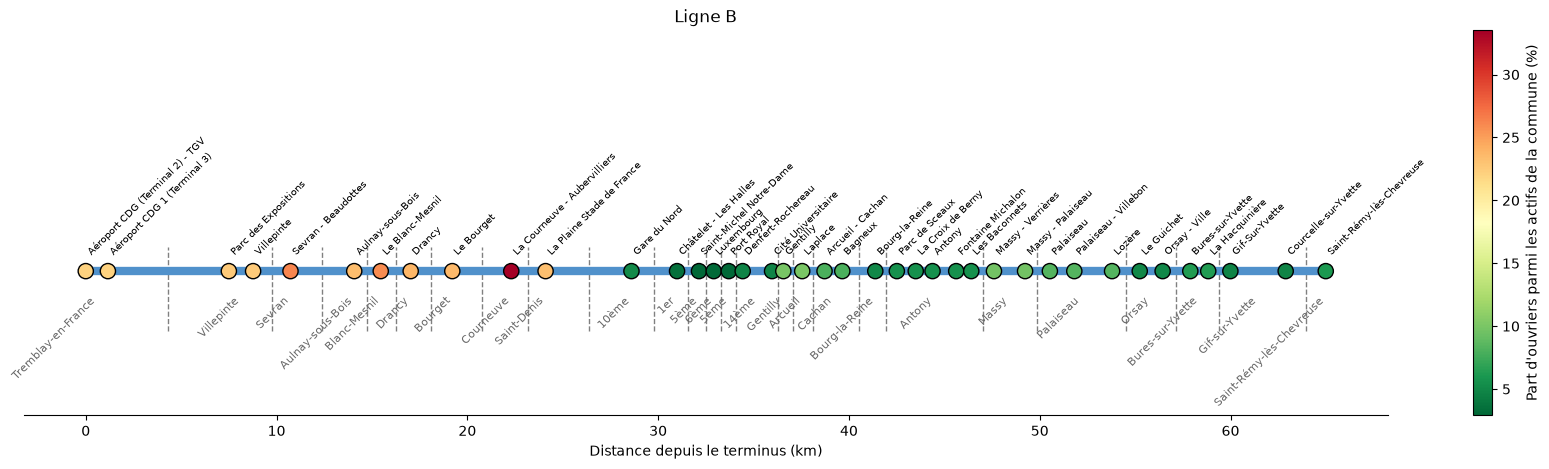

In [26]:
#CELLULE G 
num = "B"  # essaie aussi "14", "A", "B", "D"...
arrets = stations_com[stations_com["route_short_name"] == num].sort_values("position_km").reset_index(drop=True)
couleur = "#" + arrets["route_color"].iloc[0]

fig, ax = plt.subplots(figsize=(22, 5))
ax.plot(arrets["position_km"], [0] * len(arrets), color=couleur, linewidth=6, zorder=1)
points = ax.scatter(
    arrets["position_km"], [0] * len(arrets),
    c=arrets["part_ouvriers"], cmap="RdYlGn_r",  # rouge = beaucoup d'ouvriers
    s=120, edgecolor="black", zorder=2,
)

# noms des stations
for _, a in arrets.iterrows():
    ax.annotate(a["stop_name"], xy=(a["position_km"], 0), xytext=(0, 10),
                textcoords="offset points", rotation=45, fontsize=7,
                ha="left", va="bottom")

# --- délimitation des communes ---
arrets["bloc"] = (arrets["nom"] != arrets["nom"].shift()).cumsum()
blocs = arrets.groupby("bloc").agg(
    nom=("nom", "first"),
    debut=("position_km", "min"),
    fin=("position_km", "max"),
)

# trait pointillé à mi-chemin entre deux communes
for i in range(len(blocs) - 1):
    frontiere = (blocs["fin"].iloc[i] + blocs["debut"].iloc[i + 1]) / 2
    ax.vlines(frontiere, -0.25, 0.1, color="gray", linestyle="--", linewidth=1, zorder=0)

# nom de la commune, incliné sous ses stations
for _, b in blocs.iterrows():
    ax.text((b["debut"] + b["fin"]) / 2, -0.1, b["nom"],
            rotation=45, ha="right", va="top", fontsize=8, color="dimgray")

fig.colorbar(points, ax=ax, label="Part d'ouvriers parmi les actifs de la commune (%)")
ax.set_ylim(-0.6, 1)
ax.set_yticks([])
ax.set_xlabel("Distance depuis le terminus (km)")
ax.spines[["left", "top", "right"]].set_visible(False)
ax.set_title(f"Ligne {num}")
plt.show()

juste paris en carte

In [27]:
#CELLULE I
def part_par_arrondissement(df_mob, indicateur):
    """Part (en %) d'un indicateur parmi les actifs de chaque arrondissement de Paris.
    indicateur : une CSP ("Ouvriers", "Cadres"...) ou "Transports en commun"."""
    paris = df_mob[df_mob["COMMUNE"] == "75056"].copy()  # seulement les Parisiens

    # True pour les personnes concernées par l'indicateur
    if indicateur == "Transports en commun":
        cible = paris["tc"]
    else:
        cible = paris["CSP"] == indicateur

    # part pondérée par arrondissement (ARM = code de l'arrondissement)
    paris["poids_cible"] = paris["IPONDI"] * cible
    somme = paris.groupby(paris["ARM"].astype(str))[["poids_cible", "IPONDI"]].sum()
    return (somme["poids_cible"] / somme["IPONDI"] * 100).round(1).rename("part")


def carte_ligne(num, indicateur="Ouvriers", cmap="Reds"):
    """Carte de Paris : arrondissements colorés selon l'indicateur + une ligne de métro/RER."""
    # 1. fond de carte : les arrondissements avec leur valeur
    part = part_par_arrondissement(df_mob, indicateur)
    fond = arr.merge(part, left_on="INSEE_COM", right_index=True, how="left")

    ax = fond.plot(
        column="part", cmap=cmap, legend=True,
        edgecolor="white", linewidth=0.8, figsize=(10, 8),
        legend_kwds={"label": f"{indicateur} parmi les actifs (%)", "shrink": 0.6},
    )

    # nom de chaque arrondissement ("1er", "2e"...) au milieu de sa zone
    for _, r in fond.iterrows():
        p = r.geometry.representative_point()
        ax.annotate(r["nom"], (p.x, p.y), ha="center", fontsize=8, color="dimgray")

    # 2. la ligne (tous ses tracés, branches comprises), avec un liseré blanc
    trace = gpd_idfm[gpd_idfm["route_short_name"] == num]
    couleur = "#" + trace["route_color"].iloc[0]
    trace.plot(ax=ax, color="white", linewidth=7, zorder=3)
    trace.plot(ax=ax, color=couleur, linewidth=4, zorder=4)

    # 3. les stations de la ligne (points blancs, sans nom)
    arrets = gpd_stations[gpd_stations["route_short_name"] == num]
    arrets.plot(ax=ax, color="white", edgecolor="black", markersize=30, zorder=5)

    # 4. le "cut" : on zoome sur Paris (avec une petite marge de 500 m)
    xmin, ymin, xmax, ymax = arr.total_bounds
    ax.set_xlim(xmin - 500, xmax + 500)
    ax.set_ylim(ymin - 500, ymax + 500)

    ax.set_axis_off()
    ax.set_title(f"Ligne {num} : part {indicateur.lower()} par arrondissement")
    plt.show()

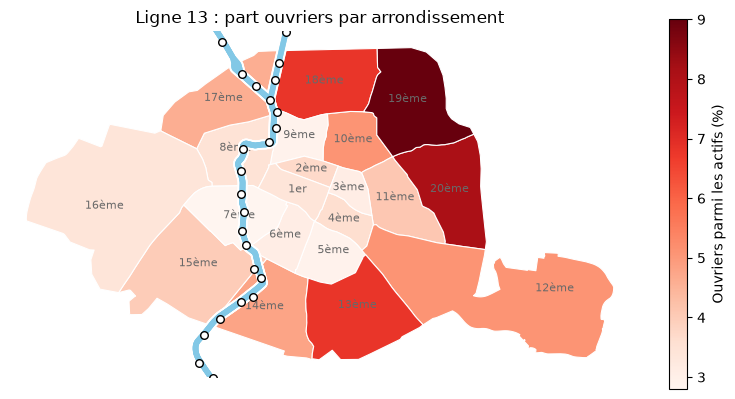

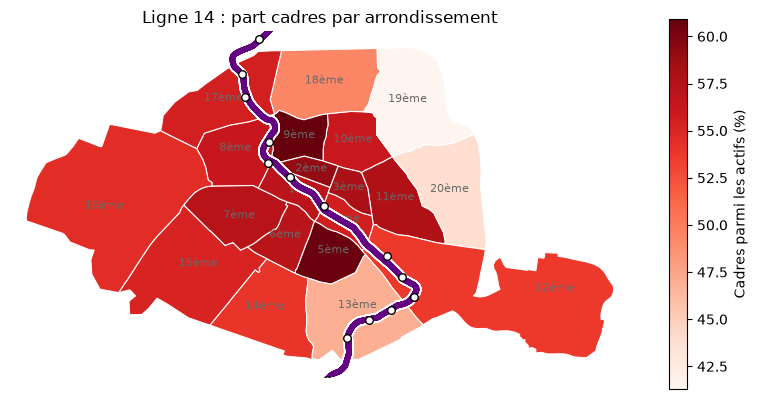

In [29]:
#CELLULE J
carte_ligne("13")                                       # ouvriers (par défaut)
carte_ligne("14", indicateur="Cadres")

la part des gens qui prennet les transports en commun

In [30]:
def carte_paris(indicateur="Ouvriers", cmap="Reds"):
    """Carte des arrondissements de Paris colorés selon un indicateur (en % des actifs)."""
    # valeur de l'indicateur pour chaque arrondissement
    part = part_par_arrondissement(df_mob, indicateur)
    fond = arr.merge(part, left_on="INSEE_COM", right_index=True, how="left")

    # arrondissements colorés
    ax = fond.plot(
        column="part", cmap=cmap, legend=True,
        edgecolor="white", linewidth=0.8, figsize=(10, 7),
        legend_kwds={"label": f"{indicateur} parmi les actifs (%)", "shrink": 0.6},
    )

    # nom et valeur de chaque arrondissement, au milieu de sa zone
    for _, r in fond.iterrows():
        p = r.geometry.representative_point()
        ax.annotate(f"{r['nom']}\n{r['part']} %", (p.x, p.y),
                    ha="center", va="center", fontsize=7, color="black")

    ax.set_axis_off()
    ax.set_title(f"Part {indicateur.lower()} parmi les actifs, par arrondissement")
    plt.show()

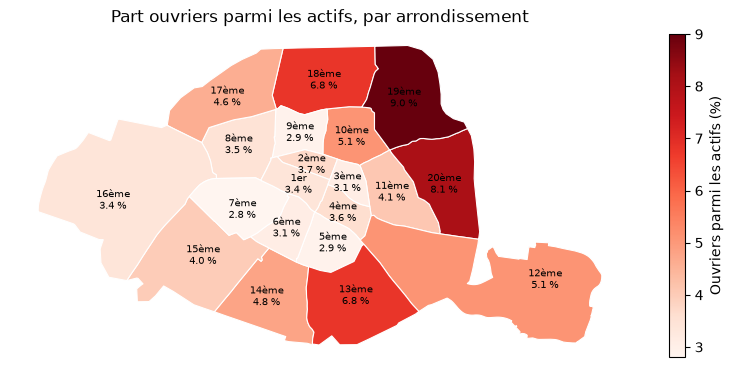

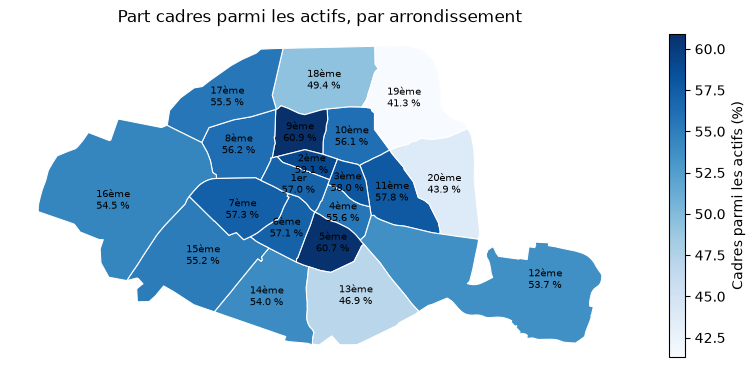

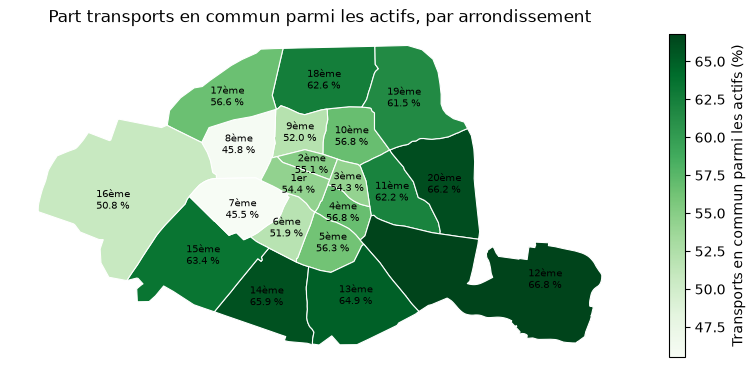

In [31]:
#CELLULE K 
carte_paris("Ouvriers")
carte_paris("Cadres", cmap="Blues")
carte_paris("Transports en commun", cmap="Greens")